In [1]:
# Importing Libraries
import ast
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt  

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [2]:
# Only get data Analyst jobs 
df_DS_US =df[(df['job_title_short']== 'Data Analyst') & (df['job_country']=='United States')].copy()
# Drop NaN values from the column for plotting
df_DS_US = df_DS_US.dropna(subset=['salary_year_avg'])


In [3]:
df_DS_US['salary_year_avg'].sample(10)

450657    135842.0
340389     84479.0
758711     55000.0
315846     74500.0
361034    100000.0
758958     87900.0
664960     90000.0
728280     35000.0
606257     82500.0
65655      90000.0
Name: salary_year_avg, dtype: float64

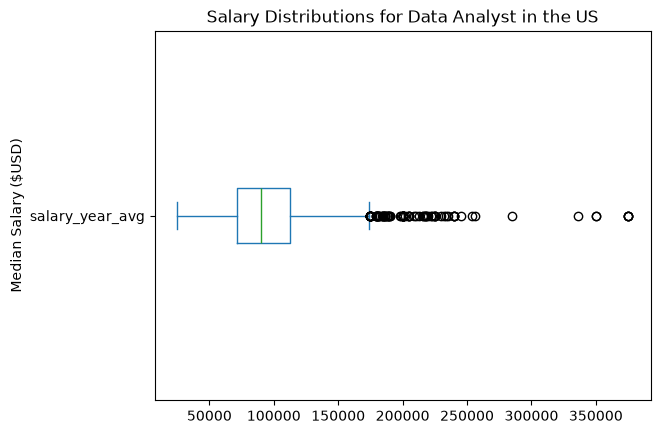

In [4]:
df_DS_US['salary_year_avg'].plot(kind = 'box', vert = False)
# Alternatively, you can use matplotlib
# plt.boxplot(df_DA_US['salary_year_avg'])

plt.title('Salary Distributions for Data Analyst in the US')
plt.ylabel('Median Salary ($USD)')
plt.show()

In [5]:
# create 3 boxplots for Data Analyst, Data Engineer, and Data Scientist job salaries in the United States.
job_titles = [ 'Data Scientist','Data Analyst', 'Data Engineer'] #Create a list
# filtter the data to appropriate job_titles
df_US = df[(df['job_title_short'].isin(job_titles)) &(df['job_country']== 'United States')]
#drop NAN values 
df_US = df_US.dropna(subset= ['salary_year_avg'])
## list of salaries for each job title
job_list = [df_US [df_US['job_title_short']== job_title]['salary_year_avg'] for job_title in job_titles]



In [6]:
job_list[0]

100       228222.0
116       114000.0
257       103128.0
450       157500.0
1257       70700.0
            ...   
785324    234500.0
785488    115000.0
785563    136400.0
785648    221875.0
785692    157500.0
Name: salary_year_avg, Length: 4553, dtype: float64

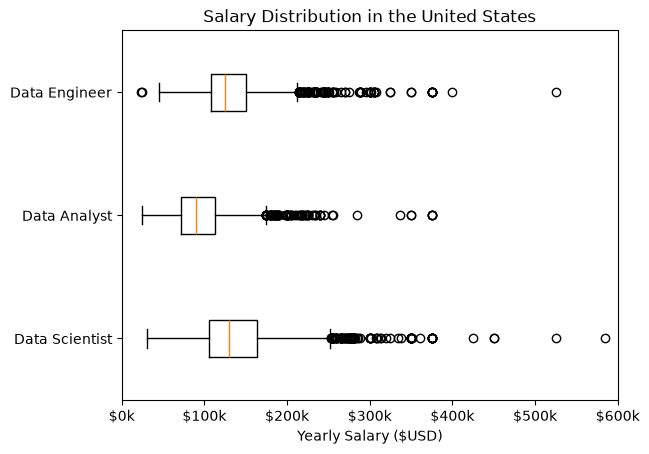

In [7]:
plt.boxplot(job_list, tick_labels= job_titles, orientation= 'horizontal')
plt.title('Salary Distribution in the United States')
plt.xlabel('Yearly Salary ($USD)')
plt.xlim(0, 600000)
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos :f'${int(x/1000)}k' ))
plt.show()

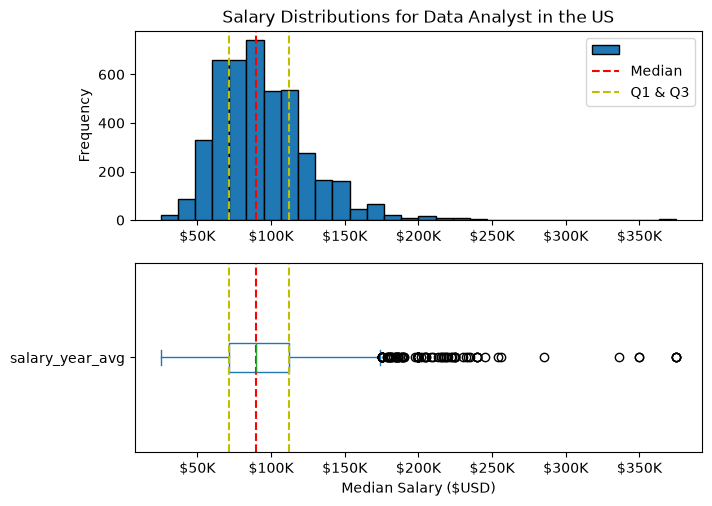

In [8]:
# plot histogram and boxplot for df_DA_US['salary_year_avg'] on same figure
fig , ax = plt.subplots(2,1)
fig.tight_layout(h_pad= 1)
# plot histogram
df_DS_US['salary_year_avg'].plot(kind = 'hist' , bins = 30 , ax= ax[0] ,edgecolor = 'black' )
ax[0].set_title('Salary Distributions for Data Analyst in the US')
ax[0].set_ylabel('Frequency')
ax[0].set_xlabel('')
ax[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos : f'${int(x/1000)}K'))
#line
ax[0].axvline(df_DS_US['salary_year_avg'].median(), color = 'r' , linestyle= '--')
ax[0].axvline(df_DS_US['salary_year_avg'].quantile(0.25), color = 'y' , linestyle = '--')
ax[0].axvline(df_DS_US['salary_year_avg'].quantile(0.75), color = 'y' , linestyle = '--')
ax[0].legend(['', 'Median', 'Q1 & Q3'])

# boxplot
df_DS_US['salary_year_avg'].plot(kind ='box' , ax = ax[1],vert = False)
ax[1].set_xlabel('Median Salary ($USD)')
ax[1].set_ylabel('')
ax[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos : f'${int(x/1000)}K'))
#line 
ax[1].axvline(df_DS_US['salary_year_avg'].median() , color ='r' , linestyle = '--')
ax[1].axvline(df_DS_US['salary_year_avg'].quantile(0.25) , color ='y' , linestyle = '--')
ax[1].axvline(df_DS_US['salary_year_avg'].quantile(0.75) , color ='y' , linestyle = '--')
plt.show()